In [2]:
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

In [3]:
import numpy as np
import mbtr.utils as ut
from scipy.linalg import hankel
from scipy.stats import expon
import scipy.special as special
import matplotlib.pyplot as plt
from mbtr.mbtr import MBT
from mbtr.utils import set_figure
from mbtr import LOSS_MAP
from Losses import BiGaussCopLoss
from Losses.BiGaussCopLoss import BiGaussCopLikelihood
from Losses import BiClaytonCopLoss
from Losses.BiClaytonCopLoss import BiClaytonCopLikelihood
from Losses import BiGumbelCopLoss
from Losses.BiGumbelCopLoss import BiGumbelCopLikelihood
from Losses import ExpLoss
from Losses.ExpLoss import JointExpLikelihood


LOSS_MAP['gaussian'] = BiGaussCopLikelihood # this line has to be added for the MBT class to recognize the subclass as a type of loss
LOSS_MAP['clayton'] = BiClaytonCopLikelihood
LOSS_MAP['gumbel'] = BiGumbelCopLikelihood
LOSS_MAP['joint_exponential'] = JointExpLikelihood

c:\Users\antho\master-thesis-project\mbtr39env\lib\site-packages\llvmlite\binding\ffi.py:175: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [4]:
import importlib
importlib.reload(BiGaussCopLoss)
importlib.reload(BiClaytonCopLoss)
importlib.reload(BiGumbelCopLoss)
importlib.reload(ExpLoss)

<module 'Losses.ExpLoss' from 'c:\\Users\\antho\\master-thesis-project\\Losses\\ExpLoss.py'>

In [5]:
import scipy.stats as stats
import openturns as ot

def clayton_tau2par(tau):
        """
        Return Clayton parameters from Kendall's tau values
        """
        return 2*(tau/(1-tau))

def gaussian_tau2par(tau):
        """
        Return Gaussian parameters from Kendall's tau values
        """
        return np.sin((np.pi/2)*tau)

def gumbel_tau2par(tau):
        """
        Return Gumbel parameters from Kendall's tau values
        """
        return 1/(1-tau)

def sample_clayton_copula(theta_array):
    """
    Sample one point from a bivariate Clayton copula for each parameter value in theta_array.
    
    Parameters:
        theta_array (np.ndarray): 1D array of positive Clayton copula parameters (theta > 0).
        seed (int, optional): Random seed for reproducibility.
    
    Returns:
        samples (np.ndarray): Array of shape (n, 2) where each row is a sample (u1, u2).
    """
    samples = []
    for theta in theta_array:
        copula = ot.ClaytonCopula(theta)
        sample = copula.getSample(1) # openturns naturally samples from the survival clayton copula
        samples.append(sample[0])

    samples = np.array(samples)
    eps = 1e-10
    samples = np.clip(samples, eps, 1 - eps)
    return samples

def sample_gaussian_copula(rho_array):
    """
    Sample one bivariate observation from a Gaussian copula for each rho in rho_array.

    Parameters:
        rho_array (np.ndarray): shape (n,), correlation coefficients in (-1, 1)

    Returns:
        np.ndarray: shape (n, 2), samples from the Gaussian copula
    """
    n = len(rho_array)
    samples = np.zeros((n, 2))

    for i, rho in enumerate(rho_array):
        if not (-1 < rho < 1):
            raise ValueError("Each rho must be in the interval (-1, 1).")

        # Define correlation matrix
        corr_matrix = ot.CorrelationMatrix(2)
        corr_matrix[0, 1] = rho

        # Create the Gaussian copula
        copula = ot.NormalCopula(corr_matrix)

        # Draw a single sample
        u = copula.getSample(1)[0]
        samples[i] = [u[0], u[1]]

    return samples

def sample_gumbel_copula(theta_array):
    """
    Sample one observation from a bivariate Gumbel copula for each theta.
    Uses OpenTURNS for sampling.
    
    Parameters:
        theta_array (np.ndarray): array of Gumbel copula parameters (theta >= 1)
    
    Returns:
        np.ndarray: shape (n, 2), copula samples in (0, 1)
    """
    samples = []
    for theta in theta_array:
        copula = ot.GumbelCopula(theta)
        sample = copula.getSample(1)
        samples.append(sample[0])
    
    samples = np.array(samples)
    # Clip to avoid 0 or 1 (required for exponential transform)
    eps = 1e-10
    samples = np.clip(samples, eps, 1 - eps)
    return samples


In [6]:
def copula_to_exponential(copula_samples, lambda1, lambda2):
    """
    Transform copula samples to exponential margins with variable rate parameters.
    
    Parameters:
        copula_samples (np.ndarray): shape (n, 2), values in (0, 1)
        lambda1 (np.ndarray): shape (n,), rate parameters for X1
        lambda2 (np.ndarray): shape (n,), rate parameters for X2
    
    Returns:
        np.ndarray: shape (n, 2), dependent exponential samples
    """
    u1, u2 = copula_samples[:, 0], copula_samples[:, 1]
    lambda1 = np.asarray(lambda1)
    lambda2 = np.asarray(lambda2)

    if np.any(u1 <= 0) or np.any(u2 <= 0):
        raise ValueError("Copula samples must be in (0, 1), not inclusive.")
    if np.any(lambda1 <= 0) or np.any(lambda2 <= 0):
        raise ValueError("Rate parameters must be > 0.")

    y1 = expon.ppf(u1, scale = 1/lambda1) #-np.log(u1) / lambda1
    y2 = expon.ppf(u2, scale = 1/lambda2) #-np.log(u2) / lambda2

    return np.column_stack((y1, y2))


In [7]:
def clip_copula_samples(samples, eps=1e-10):
    """
    Ensure copula samples are strictly inside (0, 1)^2.
    
    Parameters:
        samples (np.ndarray): shape (n, 2), values in [0, 1]
        eps (float): small buffer to keep samples strictly in (0, 1)
    
    Returns:
        np.ndarray: clipped samples in (eps, 1 - eps)
    """
    return np.clip(samples, eps, 1 - eps)

In [8]:
def mse(y, y_pred):
    return np.mean((y-y_pred)**2)

def sum_of_squares(y, y_pred):
    return np.sum((y-y_pred)**2)

def r_squared(y, y_pred, y_bar):
    return (1 - sum_of_squares(y, y_pred)/sum_of_squares(y, y_bar))

In [9]:
jointexp = JointExpLikelihood()
clayton = BiClaytonCopLikelihood()
gumbel = BiGumbelCopLikelihood()
gaussian = BiGaussCopLikelihood()

In [10]:
# Step-wise function
np.random.seed(43)
n = 10000

x = np.random.uniform(0, 1, (n, 3))
x1 = x[:, 0]
x2 = x[:, 1]
x3 = x[:, 2]

depA = (x1 < 0.4) & (x2 < 0.75)
depB = (x1 >= 0.4) & (x2 < 0.75)
depC = (x1 < 0.4) & (x2 >= 0.75)
depD = (x1 >= 0.4) & (x2 >= 0.75)
#print(np.sum(depA))
#print(np.sum(depB))
#print(np.sum(depC))
#print(np.sum(depD))

tau = np.zeros(n)
tau[depA] = 0.3
tau[depB] = 0.5
tau[depC] = 0.7
tau[depD] = 0.9

clayton_sample = clip_copula_samples(sample_clayton_copula(clayton_tau2par(tau)))
gaussian_sample = clip_copula_samples(sample_gaussian_copula(gaussian_tau2par(tau)))
gumbel_sample = clip_copula_samples(sample_gumbel_copula(gumbel_tau2par(tau)))

#plt.scatter(clayton_sample[:, 0], clayton_sample[:, 1], alpha = 0.3)
#plt.show()

#groupA = (x1>0.5)
#groupB = ~groupA

#rate1 = np.zeros(n)
#rate2 = np.zeros(n)

#rate1[groupA] = 3.0
#rate2[groupA] = 1.0

#rate1[groupB] = 0.5
#rate2[groupB] = 6.0

rate1 = np.exp(-1+3*x1 - 0.5*x3)
rate2 = np.exp(-1-0.1*x1 + 2.5*x3)

y_clayton = copula_to_exponential(clayton_sample, rate1, rate2)
y_gumbel = copula_to_exponential(gumbel_sample, rate1, rate2)
y_gauss = copula_to_exponential(gaussian_sample, rate1, rate2)

#plt.scatter(y_clayton[:, 0], y_clayton[:, 1], alpha = 0.3)
#plt.show()

In [ ]:
marginal_clayton = MBT(loss_type = "joint_exponential", n_boosts = 250, min_leaf = 2000, refit=False, learning_rate=0.1, lambda_weights=0.1).fit(x, y_clayton, do_plot=False)
marginal_gumbel = MBT(loss_type = "joint_exponential", n_boosts = 250, min_leaf = 2000, refit=False, learning_rate=0.1, lambda_weights=0.1).fit(x, y_gumbel, do_plot=False)
marginal_gaussian = MBT(loss_type = "joint_exponential", n_boosts = 250, min_leaf = 2000, refit=False, learning_rate=0.1, lambda_weights=0.1).fit(x, y_gauss, do_plot=False)

 33%|███▎      | 167/500 [01:14<02:28,  2.24it/s]


#---------------- Model fitted in 1.24e+00 min ----------------


 29%|██▊       | 143/500 [01:03<02:38,  2.26it/s]


#---------------- Model fitted in 1.06e+00 min ----------------


 31%|███▏      | 157/500 [01:11<02:35,  2.21it/s]

#---------------- Model fitted in 1.19e+00 min ----------------


In [39]:
nat_rate_clayton = marginal_clayton.predict(x)
nat_rate_gumbel = marginal_gumbel.predict(x)
nat_rate_gaussian = marginal_gaussian.predict(x)

par_clayton = np.hstack((np.exp(nat_rate_clayton[:,0].reshape(-1, 1)), np.exp(nat_rate_clayton[:,1].reshape(-1,1))))
par_gumbel = np.hstack((np.exp(nat_rate_gumbel[:,0].reshape(-1, 1)), np.exp(nat_rate_gumbel[:,1].reshape(-1,1))))
par_gaussian = np.hstack((np.exp(nat_rate_gaussian[:,0].reshape(-1, 1)), np.exp(nat_rate_gaussian[:,1].reshape(-1,1))))

In [40]:
rate = np.stack((rate1, rate2), axis = 1)
rate_bar_clayton = np.exp(jointexp.get_initial_guess(y_clayton))
rate_bar_gumbel = np.exp(jointexp.get_initial_guess(y_gumbel))
rate_bar_gauss = np.exp(jointexp.get_initial_guess(y_gauss))

# Marginal fit
print("Clayton sample rate benchmark MSE:")
print("Clayton sample rate MSE:", mse(par_clayton, rate))
print("Gumbel sample rate MSE:", mse(par_gumbel, rate))
print("Gaussian sample rate MSE:", mse(par_gaussian, rate))
print("\n")
# Marginal fit
print("Clayton sample rate R^2:", r_squared(rate, par_clayton, rate_bar_clayton))
print("Gumbel sample rate R^2:", r_squared(rate, par_gumbel, rate_bar_gumbel))
print("Gaussian sample R^2:", r_squared(rate, par_gaussian, rate_bar_gauss))
print("\n")
# Marginal fit
print("Benchmark Clayton -logL:", jointexp.tree_loss(y_clayton, np.log(rate_bar_clayton)))
print("Benchmark Gumbel -logL:", jointexp.tree_loss(y_gumbel, np.log(rate_bar_gumbel)))
print("Benchmark Gaussian -logL:", jointexp.tree_loss(y_gauss, np.log(rate_bar_gauss)))
print("Clayton sample rate -logL:", jointexp.tree_loss(y_clayton, np.log(par_clayton)))
print("Gumbel sample rate -logL:", jointexp.tree_loss(y_gumbel, np.log(par_gumbel)))
print("Gaussian sample rate -logL:", jointexp.tree_loss(y_gauss, np.log(par_gaussian)))

Clayton sample rate benchmark MSE:
Clayton sample rate MSE: 0.06243593882424321
Gumbel sample rate MSE: 0.06004507871988014
Gaussian sample rate MSE: 0.07352062358915613


Clayton sample rate R^2: 0.973844911300521
Gumbel sample rate R^2: 0.9748372561858157
Gaussian sample R^2: 0.9692435127625847


Benchmark Clayton -logL: 21537.155379542324
Benchmark Gumbel -logL: 21580.76104856618
Benchmark Gaussian -logL: 21613.721929996067
Clayton sample rate -logL: 15361.090821025173
Gumbel sample rate -logL: 15312.301580220097
Gaussian sample rate -logL: 15216.041996668951


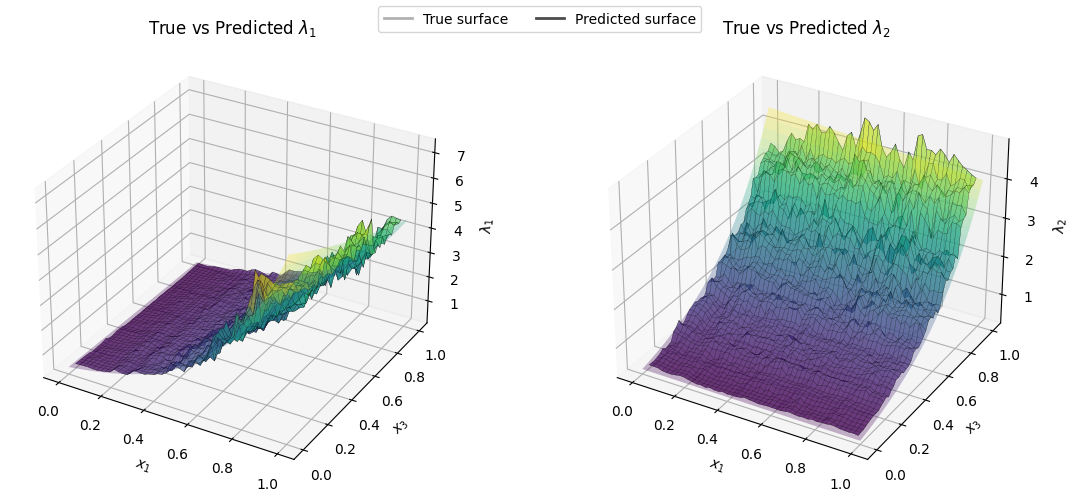

In [43]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.lines import Line2D
from scipy.interpolate import griddata

# --- Create a grid for smooth surfaces ---
grid_size = 50
X1g, X3g = np.meshgrid(np.linspace(0, 1, grid_size), np.linspace(0, 1, grid_size))

# True surfaces
lambda1_true_grid = np.exp(-1 + 3*X1g - 0.5*X3g)
lambda2_true_grid = np.exp(-1 - 0.1*X1g + 2.5*X3g)

# Predicted surfaces (use nearest-neighbor interpolation for example)

lambda1_pred_grid = griddata((x1, x3), par_gumbel[:, 0], (X1g, X3g), method='linear')
lambda2_pred_grid = griddata((x1, x3), par_gumbel[:, 1], (X1g, X3g), method='linear')

# --- Plot for lambda_1 ---
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(X1g, X3g, lambda1_true_grid, cmap='viridis',
                 alpha=0.3, edgecolor='none')
ax1.plot_surface(X1g, X3g, lambda1_pred_grid, cmap='viridis',
                 alpha=0.7, edgecolor='k', linewidth=0.2)
ax1.set_xlabel('$x_1$')
ax1.set_ylabel('$x_3$')
ax1.set_zlabel(r'$\lambda_1$')
ax1.set_title(r'True vs Predicted $\lambda_1$')

# --- Plot for lambda_2 ---
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X1g, X3g, lambda2_true_grid, cmap='viridis',
                 alpha=0.3, edgecolor='none')
ax2.plot_surface(X1g, X3g, lambda2_pred_grid, cmap='viridis',
                 alpha=0.7, edgecolor='k', linewidth=0.2)
ax2.set_xlabel('$x_1$')
ax2.set_ylabel('$x_3$')
ax2.set_zlabel(r'$\lambda_2$')
ax2.set_title(r'True vs Predicted $\lambda_2$')

# --- Add a shared legend ---
legend_elements = [
    Line2D([0], [0], color='black', lw=2, label='True surface', alpha=0.3),
    Line2D([0], [0], color='black', lw=2, label='Predicted surface', alpha=0.7)
]
fig.legend(handles=legend_elements, loc='upper center', ncol=2)

plt.tight_layout()
plt.show()

In [87]:
# fit copula to true copula observations (U)
mcop_clayton = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "clayton", refit = False, min_leaf = 1000, verbose = 0, lambda_weights = 0.1).fit(x, clayton_sample, do_plot = False)
mcop_gumbel = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gumbel", refit = False, min_leaf = 1000, verbose = 0, lambda_weights=0.1).fit(x, gumbel_sample, do_plot = False)
mcop_gaussian = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gaussian", refit = False, min_leaf = 1000, verbose = 0, lambda_weights=0.1).fit(x, gaussian_sample, do_plot = False)

 36%|███▌      | 89/250 [01:20<02:25,  1.11it/s]


#---------------- Model fitted in 1.34e+00 min ----------------


 33%|███▎      | 83/250 [01:03<02:07,  1.31it/s]


#---------------- Model fitted in 1.06e+00 min ----------------


 38%|███▊      | 94/250 [01:25<02:21,  1.10it/s]

#---------------- Model fitted in 1.42e+00 min ----------------


In [88]:
reparam_theta_clayton = mcop_clayton.predict(x)
reparam_theta_gumbel = mcop_gumbel.predict(x)
reparam_theta_gaussian = mcop_gaussian.predict(x)

#theta_clayton = np.exp(reparam_theta_clayton)
#theta_gaussian = (2/np.pi)*np.arctan(reparam_theta_gaussian)
#theta_gumbel = np.exp(reparam_theta_gumbel)+1

tau_clayton = special.expit(reparam_theta_clayton) #theta_clayton/(theta_clayton + 2)
tau_gumbel = special.expit(reparam_theta_gumbel) #1-1/theta_gumbel
tau_gaussian = special.expit(reparam_theta_gaussian) #(2/np.pi)*np.arcsin(theta_gaussian)

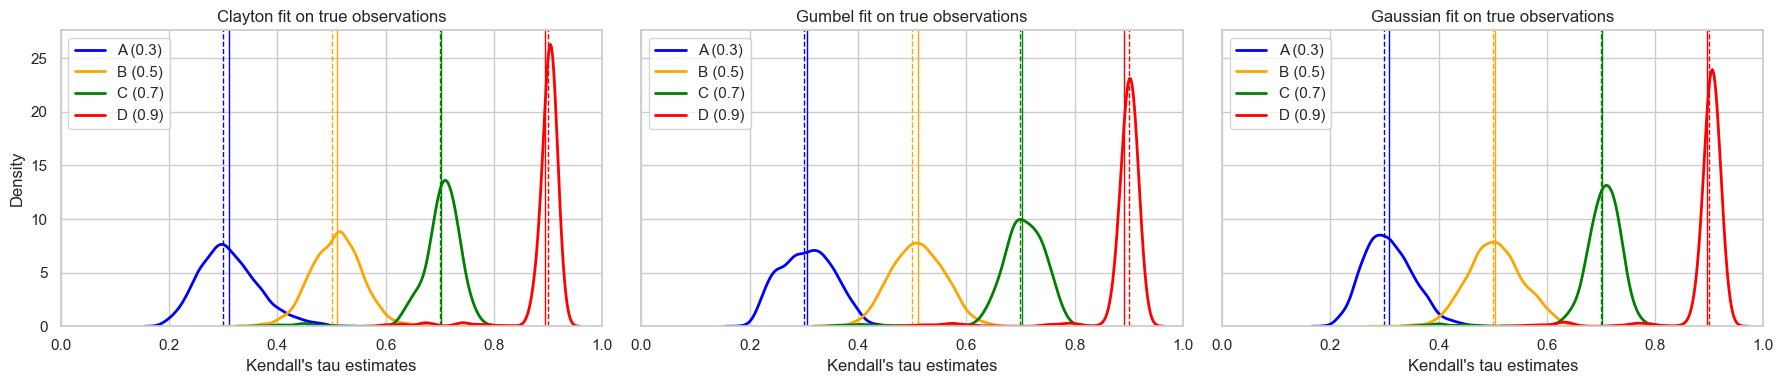

In [89]:
#import matplotlib.pyplot as plt
import seaborn as sns

# Style
sns.set_theme(style="whitegrid")

# Labels and colors
group_labels = ["A (0.3)", "B (0.5)", "C (0.7)", "D (0.9)"]
colors = ["blue", "orange", "green", "red"]


# Create subplots
true_cop_fig, true_cop_axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

# Data for each copula model
models_tau = {
    "Clayton": tau_clayton,
    "Gumbel": tau_gumbel,
    "Gaussian": tau_gaussian
}

# Indices per group
dep_groups = [depA, depB, depC, depD]
true_taus = [0.3, 0.5, 0.7, 0.9]

# Plot
for ax, (model_name, tau_data) in zip(true_cop_axes, models_tau.items()):
    for dep_idx, label, color, true_val in zip(dep_groups, group_labels, colors, true_taus):
        estimates = tau_data[dep_idx, 0]

        # KDE
        sns.kdeplot(estimates, ax=ax, label=label, color=color, linewidth=2)

        # True line (dashed)
        ax.axvline(true_val, color=color, linestyle='--', linewidth=1)

        # Mean estimate line (solid)
        mean_val = np.mean(estimates)
        ax.axvline(mean_val, color=color, linestyle='-', linewidth=1)
        # KDE line
        #sns.kdeplot(tau_data[dep_idx, 0], ax=ax, label=label, color=color, linewidth=2)
        # Vertical line for true tau
        #ax.axvline(tau_true, color=color, linestyle='--', linewidth=1)

    ax.set_xlim(0, 1)
    ax.set_xlabel("Kendall's tau estimates")
    ax.set_ylabel("Density")
    ax.set_title(f"{model_name} fit on true observations")
    ax.legend()

plt.tight_layout()
plt.show()


In [90]:
# compute pseudo-observations based on estimated marginal CDF
cdf_obs_clayton1 = expon.cdf(y_clayton[:, 0], scale = 1/par_clayton[:, 0]).reshape(-1,1)
cdf_obs_clayton2 = expon.cdf(y_clayton[:, 1], scale = 1/par_clayton[:, 1]).reshape(-1,1)
cdf_obs_clayton = np.hstack((cdf_obs_clayton1, cdf_obs_clayton2))

cdf_obs_gumbel1 = expon.cdf(y_gumbel[:, 0], scale = 1/par_gumbel[:, 0]).reshape(-1,1)
cdf_obs_gumbel2 = expon.cdf(y_gumbel[:, 1], scale = 1/par_gumbel[:, 1]).reshape(-1,1)
cdf_obs_gumbel = np.hstack((cdf_obs_gumbel1, cdf_obs_gumbel2))

cdf_obs_gaussian1 = expon.cdf(y_gauss[:, 0], scale = 1/par_gaussian[:, 0]).reshape(-1,1)
cdf_obs_gaussian2 = expon.cdf(y_gauss[:, 1], scale = 1/par_gaussian[:, 1]).reshape(-1,1)
cdf_obs_gaussian = np.hstack((cdf_obs_gaussian1, cdf_obs_gaussian2))

In [91]:
# fit copula to cdf-based pseudo copula observations (V)
cdf_cop_clayton = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "clayton", refit = False, min_leaf = 1000, lambda_weights=0.1).fit(x, cdf_obs_clayton, do_plot = False)
cdf_cop_gumbel = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gumbel", refit = False, min_leaf = 1000, lambda_weights=0.1).fit(x, cdf_obs_gumbel, do_plot = False)
cdf_cop_gaussian = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gaussian", refit = False, min_leaf = 1000, lambda_weights=0.1).fit(x, cdf_obs_gaussian, do_plot = False)

 41%|████      | 102/250 [01:07<01:38,  1.51it/s]


#---------------- Model fitted in 1.13e+00 min ----------------


 30%|██▉       | 74/250 [00:47<01:52,  1.57it/s]


#---------------- Model fitted in 7.88e-01 min ----------------


 37%|███▋      | 92/250 [01:10<02:00,  1.31it/s]


#---------------- Model fitted in 1.17e+00 min ----------------


In [92]:
cdf_reparam_theta_clayton = cdf_cop_clayton.predict(x)
cdf_reparam_theta_gumbel = cdf_cop_gumbel.predict(x)
cdf_reparam_theta_gaussian = cdf_cop_gaussian.predict(x)

#cdf_theta_clayton = np.exp(cdf_reparam_theta_clayton)
#cdf_theta_gaussian = (2/np.pi)*np.arctan(cdf_reparam_theta_gaussian)
#cdf_theta_gumbel = np.exp(cdf_reparam_theta_gumbel)+1

cdf_tau_clayton = special.expit(cdf_reparam_theta_clayton) #cdf_theta_clayton/(cdf_theta_clayton + 2)
cdf_tau_gumbel = special.expit(cdf_reparam_theta_gumbel) #1-1/cdf_theta_gumbel
cdf_tau_gaussian = special.expit(cdf_reparam_theta_gaussian) #(2/np.pi)*np.arcsin(cdf_theta_gaussian)

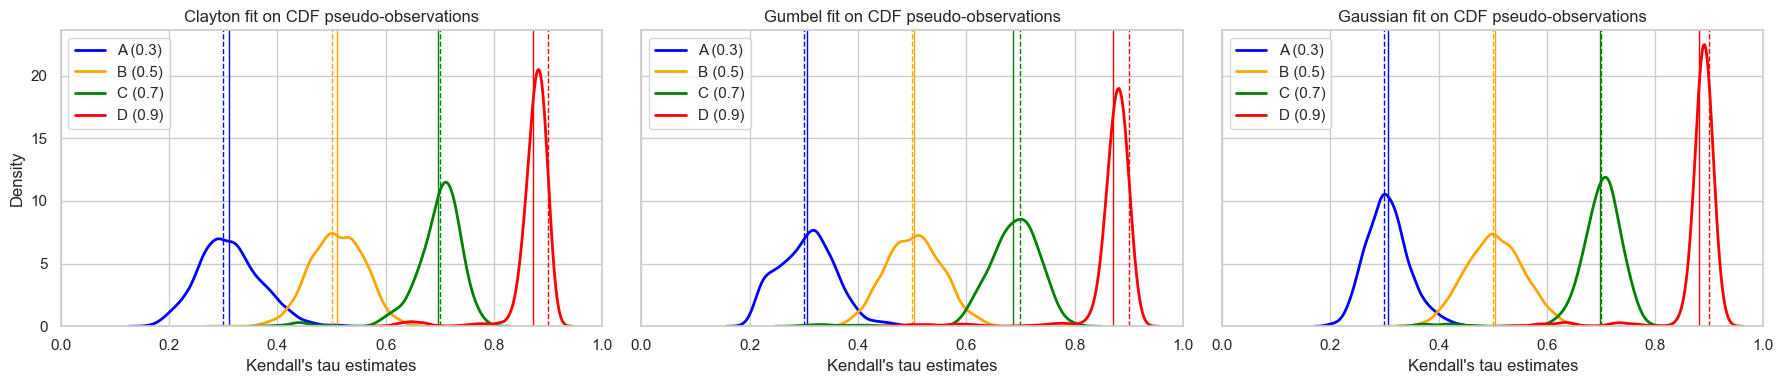

In [93]:
#import matplotlib.pyplot as plt
import seaborn as sns

# Style and setup
sns.set_theme(style="whitegrid")

# Group labels, colors, and true Kendall's tau values
group_labels = ["A (0.3)", "B (0.5)", "C (0.7)", "D (0.9)"]
colors = ["blue", "orange", "green", "red"]
true_taus = [0.3, 0.5, 0.7, 0.9]
dep_groups = [depA, depB, depC, depD]

# Copula model tau estimates
cdf_models_tau = {
    "Clayton": cdf_tau_clayton,
    "Gumbel": cdf_tau_gumbel,
    "Gaussian": cdf_tau_gaussian
}

# Subplots
cdf_cop_fig, cdf_cop_axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

for ax, (model_name, tau_data) in zip(cdf_cop_axes, cdf_models_tau.items()):
    for dep_idx, label, color, true_val in zip(dep_groups, group_labels, colors, true_taus):
        estimates = tau_data[dep_idx, 0]

        # KDE
        sns.kdeplot(estimates, ax=ax, label=label, color=color, linewidth=2)

        # True line (dashed)
        ax.axvline(true_val, color=color, linestyle='--', linewidth=1)

        # Mean estimate line (solid)
        mean_val = np.mean(estimates)
        ax.axvline(mean_val, color=color, linestyle='-', linewidth=1)
        # KDE line
        #sns.kdeplot(tau_data[dep_idx, 0], ax=ax, label=label, color=color, linewidth=2)
        # Vertical line for true tau
        #ax.axvline(tau_true, color=color, linestyle='--', linewidth=1)

    ax.set_xlim(0, 1)
    ax.set_xlabel("Kendall's tau estimates")
    ax.set_ylabel("Density")
    ax.set_title(f"{model_name} fit on CDF pseudo-observations")
    ax.legend()

plt.tight_layout()
plt.show()


In [94]:
# Copula fit on true observation (U)
print("Clayton U tau MSE:", mse(tau_clayton, tau))
print("Gumbel U tau MSE:", mse(tau_gumbel, tau))
print("Gaussian U tau MSE:", mse(tau_gaussian, tau))
print("\n")
# Copula fit on pseudo-observation (V)
print("Clayton V tau MSE:", mse(cdf_tau_clayton, tau))
print("Gumbel V tau MSE:", mse(cdf_tau_gumbel, tau))
print("Gaussian V tau MSE:", mse(cdf_tau_gaussian, tau))

Clayton U tau MSE: 0.08034803276449622
Gumbel U tau MSE: 0.0808042588198486
Gaussian U tau MSE: 0.08091122084378674


Clayton V tau MSE: 0.07777378378722263
Gumbel V tau MSE: 0.07827719135095645
Gaussian V tau MSE: 0.07939598922600394


In [95]:
tau_bar_clayton = special.expit(clayton.get_initial_guess(clayton_sample))
tau_bar_gumbel = special.expit(gumbel.get_initial_guess(gumbel_sample))
tau_bar_gauss = special.expit(gaussian.get_initial_guess(gaussian_sample))

cdf_tau_bar_clayton = special.expit(clayton.get_initial_guess(cdf_obs_clayton))
cdf_tau_bar_gumbel = special.expit(gumbel.get_initial_guess(cdf_obs_gumbel))
cdf_tau_bar_gauss = special.expit(gaussian.get_initial_guess(cdf_obs_gaussian))

# Copula fit on true observation (U)
print("Clayton U tau R^2:", r_squared(tau.reshape(-1,1), tau_clayton, tau_bar_clayton))
print("Gumbel U tau R^2:", r_squared(tau.reshape(-1,1), tau_gumbel, tau_bar_gumbel))
print("Gaussian U tau R^2:", r_squared(tau.reshape(-1,1), tau_gaussian, tau_bar_gauss))
print("\n")
# Copula fit on pseudo-observation (V)
print("Clayton V tau R^2:", r_squared(tau.reshape(-1,1), cdf_tau_clayton, cdf_tau_bar_clayton))
print("Gumbel V tau R^2:", r_squared(tau.reshape(-1,1), cdf_tau_gumbel, cdf_tau_bar_gumbel))
print("Gaussian V tau R^2:", r_squared(tau.reshape(-1,1), cdf_tau_gaussian, cdf_tau_bar_gauss))

Clayton U tau R^2: 0.9393476492371665
Gumbel U tau R^2: 0.9382477753518229
Gaussian U tau R^2: 0.9433053292753696


Clayton V tau R^2: 0.9319137787512255
Gumbel V tau R^2: 0.9286242946038883
Gaussian V tau R^2: 0.9430748124596486


In [96]:
# Copula fit on true observation (U)
print("Benchmark Clayton U tau -logL:", clayton.tree_loss(clayton_sample, special.logit(tau_bar_clayton)))
print("Benchmark Gumbel U tau -logL:", gumbel.tree_loss(gumbel_sample, special.logit(tau_bar_gumbel)))
print("Benchmark Gaussian U tau -logL:", gaussian.tree_loss(gaussian_sample, special.logit(tau_bar_gauss)))
print("Clayton U tau -logL:", clayton.tree_loss(clayton_sample, special.logit(tau_clayton)))
print("Gumbel U tau -logL:", gumbel.tree_loss(gumbel_sample, special.logit(tau_gumbel)))
print("Gaussian U tau -logL:", gaussian.tree_loss(gaussian_sample, special.logit(tau_gaussian)))
print("\n")
# Copula fit on pseudo-observation (V)
print("Benchmark Clayton V tau -logL:", clayton.tree_loss(cdf_obs_clayton, special.logit(cdf_tau_bar_clayton)))
print("Benchmark Gumbel V tau -logL:", gumbel.tree_loss(cdf_obs_gumbel, special.logit(cdf_tau_bar_gumbel)))
print("Benchmark Gaussian V tau -logL:", gaussian.tree_loss(cdf_obs_gaussian, special.logit(cdf_tau_bar_gauss)))
print("Clayton V tau -logL:", clayton.tree_loss(cdf_obs_clayton, special.logit(cdf_tau_clayton)))
print("Gumbel V tau -logL:", gumbel.tree_loss(cdf_obs_gumbel, special.logit(cdf_tau_gumbel)))
print("Gaussian V tau -logL:", gaussian.tree_loss(cdf_obs_gaussian, special.logit(cdf_tau_gaussian)))

Benchmark Clayton U tau -logL: -3955.5699606687695
Benchmark Gumbel U tau -logL: -3739.664219744911
Benchmark Gaussian U tau -logL: -3155.54307885698
Clayton U tau -logL: -6572.457407513882
Gumbel U tau -logL: -5988.075901441181
Gaussian U tau -logL: -5657.8269615108575


Benchmark Clayton V tau -logL: -3896.992836488385
Benchmark Gumbel V tau -logL: -3566.9271287920083
Benchmark Gaussian V tau -logL: -3075.243121094079
Clayton V tau -logL: -6228.460180914004
Gumbel V tau -logL: -5497.929766386034
Gaussian V tau -logL: -5343.0726085622
